# Практика №3. Основы нейросетей и компьютерного зрения (CNN + Transfer Learning)

**Сдающий:** Макеев Г. Б. &nbsp;·&nbsp; **Группа:** BHEBDPS-24-MII-5<br>
**Дисциплина:** Методы искусственного интеллекта I (ТюмГУ)<br>
**Дата:** 18 октября 2026<br>
**Инструменты:** Python 3.12, PyTorch 2.14 (CPU), torchvision, matplotlib<br>
**Датасет:** CIFAR-10 — 60 000 цветных картинок 32×32, 10 классов (<https://cave.cs.toronto.edu/kriz/cifar.html>)

---

## Что требовалось (чек-лист задания и где это в отчёте)

| Пункт задания | Где смотреть | Статус |
|---|---|---|
| Этап 1. Загрузка CIFAR-10, аугментации (`RandomHorizontalFlip`, `RandomCrop`, `ColorJitter`), нормализация | раздел 1 | ✅ |
| Этап 2. ResNet18 с весами ImageNet, заморозка свёрточных слоёв, замена `nn.Linear(512, 1000)` → `nn.Linear(512, 10)`, Adam только на новый слой | раздел 2 | ✅ |
| Этап 3. Цикл обучения (эпохи), `CrossEntropyLoss`, accuracy и confusion matrix на тесте, показ картинок с ошибками | раздел 3 | ✅ |
| :star: Разморозить последние слои ResNet18, дообучить сеть (fine-tuning), сравнить accuracy «до» и «после» | раздел 4 | ✅ |
| ДЗ лекции 3: нейрон с Sigmoid без PyTorch (сдаётся отдельным файлом) | раздел 5 | ✅ |

**Организация работы.** Задание разложено по папкам, в каждой — скрипт, графики и свой отчёт
`results.md`: `01_data_augmentation/`, `02_model_adaptation/`, `03_train_eval/`,
`04_fine_tuning_star/`, `05_homework_neuron/`, общий код — в `common/`. Этот ноутбук — сводный отчёт.

> Особенность окружения: GPU нет (Intel Iris Xe), поэтому всё обучение идёт на CPU.
> Из-за этого взята стратифицированная подвыборка обучения — 10 000 картинок (по 1000 на класс),
> а тест — полный (10 000 картинок). Один и тот же сид (`SEED = 42`) и один и тот же файл
> индексов подвыборки используются всеми этапами, поэтому сравнение моделей честное.

## Служебный код отчёта

In [1]:
# служебная ячейка: загружаем метрики реальных прогонов и учимся показывать «скриншоты»
import json
from pathlib import Path
from IPython.display import Image, display, Markdown

ROOT = Path.cwd()

def load(path):
    return json.loads((ROOT / path).read_text(encoding="utf-8"))

m1 = load("01_data_augmentation/outputs/metrics.json")   # данные и аугментации
m2 = load("02_model_adaptation/outputs/metrics.json")    # адаптация ResNet18
m3 = load("03_train_eval/outputs/metrics.json")          # обучение головы и оценка
m4 = load("04_fine_tuning_star/outputs/metrics.json")    # fine-tuning и «с нуля»
m5 = load("05_homework_neuron/outputs/metrics.json")     # ДЗ: нейрон с сигмоидой

def show(*paths, width=820):
    # показать «скриншот» из outputs/: подпись — относительный путь к файлу
    for path in paths:
        p = ROOT / path
        print(f"↓ {path}" if p.exists() else f"[НЕТ ФАЙЛА: {path}]")
        if p.exists():
            display(Image(filename=str(p), width=width))

print("артефакты прогонов загружены")

артефакты прогонов загружены


In [2]:
# сверка: цифры в тексте отчёта против metrics.json реальных прогонов
summary = {
    "01 subset train": f"{m1['subset_size']} картинок (по {m1['per_class']} на класс)",
    "02 всего параметров": m2["param_stats"]["total_human"],
    "02 обучаемых (голова fc)": f"{m2['param_stats']['trainable_human']} = "
                                f"{m2['param_stats']['trainable_share_pct']}% модели",
    "03 accuracy (только голова)": m3["test"]["accuracy"],
    "03 macro-F1": m3["test"]["macro_f1"],
    "03 accuracy при BN train (контроль)": [r["acc"] for r in m3["bn_compare"] if r["bn_mode"] == "train"][0],
    "04 accuracy после fine-tuning layer4+fc": m4["results"]["layer4"]["accuracy"],
    "04 accuracy обучение с нуля": m4["results"]["scratch"]["accuracy"],
    "05 расхождение градиентов (аналитика vs численно)": f"{m5['gradient_check']['max_abs_diff']:.2e}",
}
for k, v in summary.items():
    print(f"{k:<52} {v}")

01 subset train                                      10000 картинок (по 1000 на класс)
02 всего параметров                                  11.18 млн
02 обучаемых (голова fc)                             5.1 тыс. = 0.046% модели
03 accuracy (только голова)                          0.6059
03 macro-F1                                          0.6049
03 accuracy при BN train (контроль)                  0.401
04 accuracy после fine-tuning layer4+fc              0.6499
04 accuracy обучение с нуля                          0.4257
05 расхождение градиентов (аналитика vs численно)    8.35e-12


---
# 1. Этап 1 — загрузка данных и аугментации

**Шаги:** скачиваем CIFAR-10, смотрим структуру (тензор 32×32×3, значения 0…255), делаем
стратифицированную подвыборку, задаём аугментации и нормализацию.

**Аугментации (искусственное расширение датасета):**

```python
transforms.Compose([
    transforms.RandomCrop(32, padding=4),                 # сдвиг ±4 px: объект может быть не в центре
    transforms.RandomHorizontalFlip(p=0.5),               # отражение: кошка слева = кошка справа
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),  # свет/цвет не должны мешать
    transforms.ToTensor(),                                # PIL 0…255 -> тензор 0…1, CHW
    transforms.Normalize(mean, std),                      # (x - mean) / std
])
```

Для теста — только `ToTensor` + `Normalize` (никаких случайностей, иначе метрики «плывут»).

**Нормализация:** привели пиксели к нулевому среднему и единичной дисперсии. Посчитали реальные
mean/std подвыборки и сравнили со стандартными константами CIFAR-10 — расхождение меньше 1 %,
поэтому используем константы.

посчитано на 5000 картинках: mean=[0.4913, 0.4814, 0.4445], std=[0.2476, 0.2445, 0.2627]
константы практики:             mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616]
обучение: 10000 картинок, тест: 10000 картинок
↓ 01_data_augmentation/outputs/03_samples.png


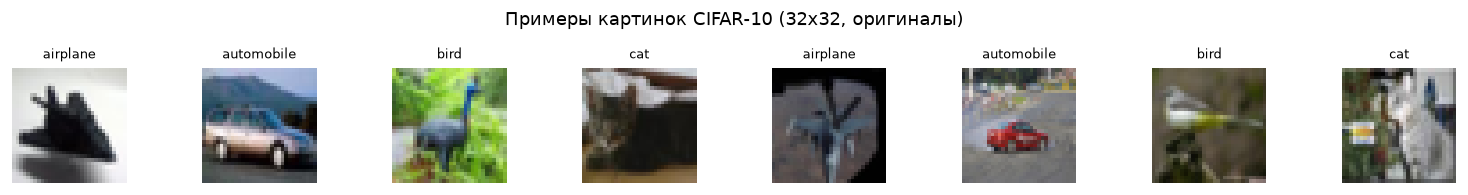

↓ 01_data_augmentation/outputs/04_augmentations.png


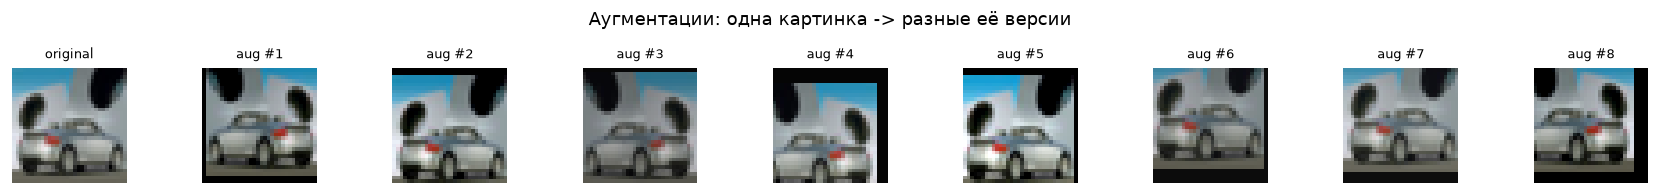

In [3]:
stats = m1["normalization"]
print(f"посчитано на {stats['n_images']} картинках: mean={stats['mean']}, std={stats['std']}")
print("константы практики:             "
      "mean=[0.4914, 0.4822, 0.4465], std=[0.247, 0.2435, 0.2616]")
print(f"обучение: {m1['subset_size']} картинок, тест: {m1['test_full']} картинок")
show("01_data_augmentation/outputs/03_samples.png",
     "01_data_augmentation/outputs/04_augmentations.png")

**Комментарий к «скриншотам».** Первый рисунок — примеры из датасета: видно, что даже 32×32
достаточно, чтобы различать «птица / самолёт / кошка». Второй — одна и та же картинка после
восьми случайных применений аугментаций: объект сдвигается и меняет цвет, но остаётся тем же
классом. Именно это заставляет модель учить **объект**, а не конкретные пиксели.

---
# 2. Этап 2 — адаптация предобученной модели (Transfer Learning)

**Идея.** ResNet18 уже обучен на ImageNet (1.2 млн картинок, 1000 классов): его свёрточные слои
умеют находить края, текстуры и формы. Мы берём эти признаки и переучиваем только последний слой
под свои 10 классов.

```python
model = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)  # веса ImageNet
for p in model.parameters():
    p.requires_grad = False                       # заморозили свёрточные слои
model.fc = nn.Linear(512, 10)                     # было nn.Linear(512, 1000), стало под CIFAR-10
optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=1e-2)
```

| | Значение |
|---|---|
| Всего параметров | 11.18 млн |
| Обучaемых (голова `fc`) | 5.1 тыс. = **0.046%** модели |
| Заморожено | 11,176,512 |

Обучаем 0.05 % весов — это и есть «стоять на плечах гигантов»: обучение занимает минуты на CPU
и не требует миллионов картинок.

**Как CNN «видит» картинку.** Ниже — фильтры первого слоя (детекторы краёв и цветовых переходов)
и карты активаций предобученной модели на разной глубине: от простых паттернов (`conv1`) к частям
объектов (`layer3`). Последний рисунок — те же слои со **случайными** весами: осмысленных признаков
нет. Это и есть разница между «обучено на ImageNet» и «чистый лист».

↓ 02_model_adaptation/outputs/01_conv1_filters.png


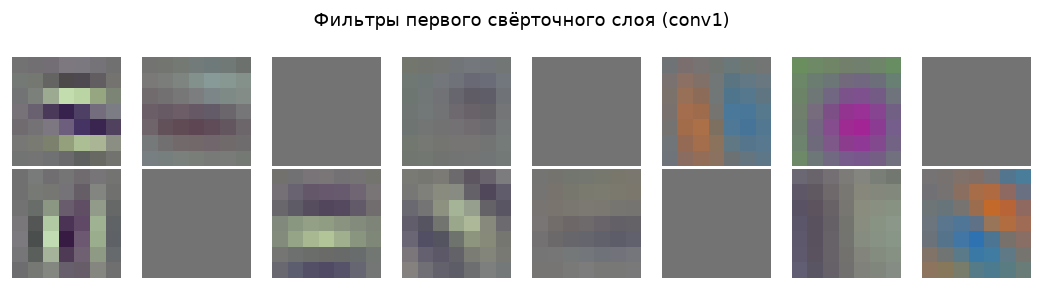

↓ 02_model_adaptation/outputs/02_input_image.png


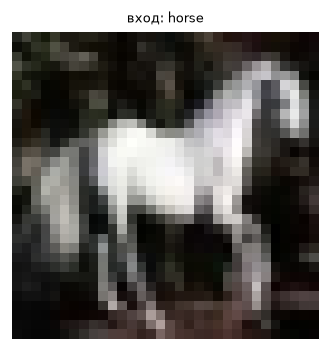

↓ 02_model_adaptation/outputs/03_feature_maps_pretrained.png


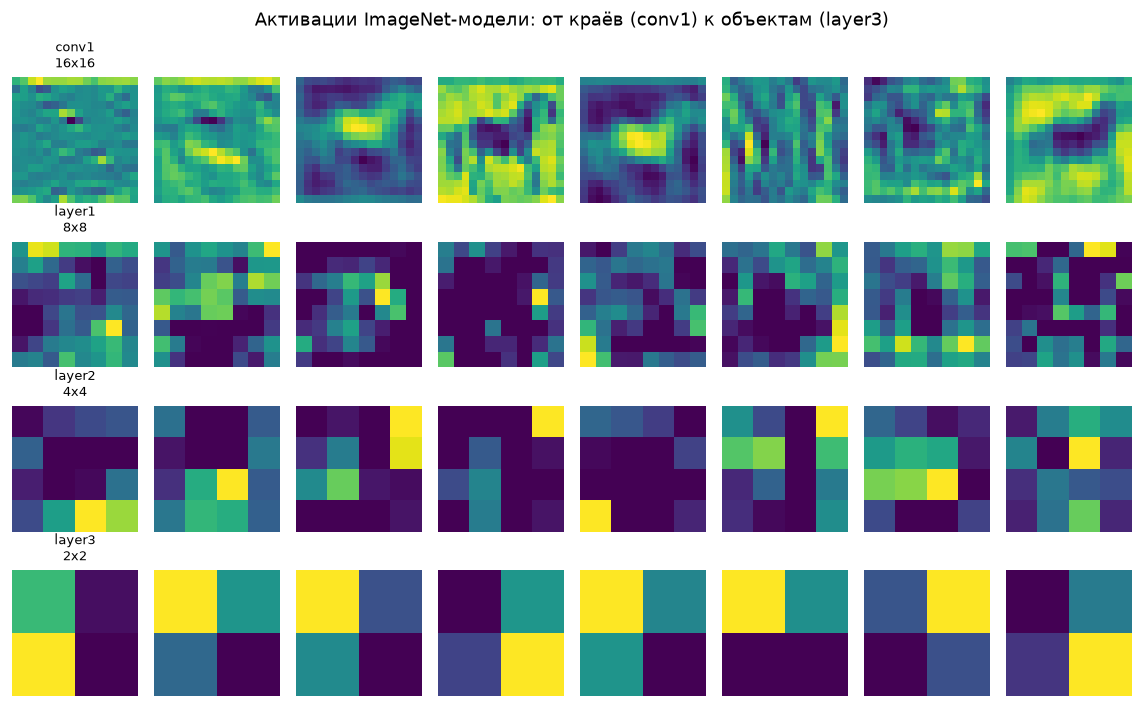

↓ 02_model_adaptation/outputs/04_feature_maps_random.png


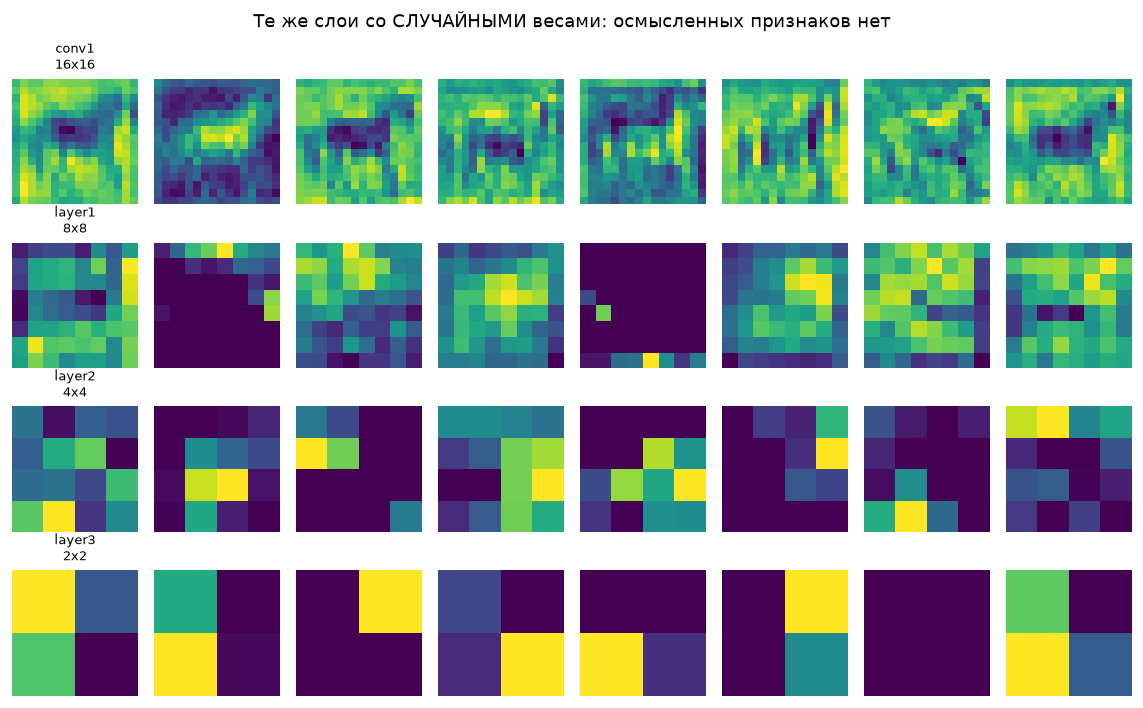

In [4]:
show("02_model_adaptation/outputs/01_conv1_filters.png", width=700)
show("02_model_adaptation/outputs/02_input_image.png", width=180)
show("02_model_adaptation/outputs/03_feature_maps_pretrained.png", width=780)
show("02_model_adaptation/outputs/04_feature_maps_random.png", width=780)

**Техническая проверка.** Прогнали тензор через блоки и вывели формы:
`input (2,3,32,32)` → `conv1 (2,64,16,16)` → `maxpool (2,64,8,8)` → `layer1 (2,64,8,8)` →
`layer2 (2,128,4,4)` → `layer3 (2,256,2,2)` → `layer4 (2,512,1,1)` → `flatten (2,512)` → `fc (2,10)`.

Отсюда важное инженерное наблюдение: стандартный ResNet18 рассчитан на 224×224 (первый слой —
свёртка 7×7 со `stride=2` плюс `MaxPool`), поэтому на картинке 32×32 после `layer4` остаётся карта
признаков **1×1** — голова видит «усреднённое» представление картинки. В `common/model.py`
предусмотрены варианты лечения (`stem="nopool"`, `stem="cifar"` за счёт свёртки 3×3 со `stride=1`);
в основном прогоне оставлен стандартный вариант из задания.

---
# 3. Этап 3 — обучение и оценка

**Шаги:** обучаем голову 15 эпох Adam'ом (`lr = 1e-2` с косинусным затуханием), функция потерь —
`CrossEntropyLoss`; затем считаем accuracy на полном тесте (10 000 картинок), матрицу ошибок и
показываем картинки, на которых модель ошиблись.

**История обучения**

| Эпоха | lr | train loss | train acc | test loss | test acc | время |
|---|---|---|---|---|---|---|
| 1 | 1.00e-02 | 1.4710 | 0.4798 | 1.2665 | 0.5597 | 9.2 с |
| 2 | 9.89e-03 | 1.2800 | 0.5465 | 1.3327 | 0.5477 | 8.9 с |
| 3 | 9.58e-03 | 1.2392 | 0.5638 | 1.3073 | 0.5578 | 9.4 с |
| 4 | 9.06e-03 | 1.2275 | 0.5659 | 1.2761 | 0.5709 | 9.2 с |
| 5 | 8.38e-03 | 1.2083 | 0.5778 | 1.2067 | 0.5870 | 9.1 с |
| 6 | 7.55e-03 | 1.1666 | 0.5905 | 1.2113 | 0.5877 | 9.5 с |
| 7 | 6.61e-03 | 1.1570 | 0.5861 | 1.2092 | 0.5881 | 10.2 с |
| 8 | 5.61e-03 | 1.1400 | 0.5967 | 1.1891 | 0.5876 | 9.9 с |
| 9 | 4.59e-03 | 1.1275 | 0.6050 | 1.2368 | 0.5784 | 8.5 с |
| 10 | 3.59e-03 | 1.1439 | 0.5932 | 1.1609 | 0.5960 | 9.1 с |
| 11 | 2.65e-03 | 1.0869 | 0.6177 | 1.1843 | 0.5861 | 10.0 с |
| 12 | 1.82e-03 | 1.0717 | 0.6236 | 1.1419 | 0.6030 | 10.6 с |
| 13 | 1.14e-03 | 1.0694 | 0.6198 | 1.1213 | 0.6065 | 13.8 с |
| 14 | 6.24e-04 | 1.0554 | 0.6280 | 1.1280 | 0.6046 | 11.0 с |
| 15 | 3.07e-04 | 1.0586 | 0.6227 | 1.1157 | 0.6059 | 10.7 с |

**Итог на тесте:** **accuracy = 0.6059**, macro-F1 = 0.6049,
loss = 1.1157. Обучение заняло 2.5 мин на CPU
(1982.8 картинок/с при инференсе).

**Метрики по классам**

| Класс | Precision | Recall | F1 | Support |
|---|---|---|---|---|
| airplane | 0.621 | 0.664 | 0.642 | 1000 |
| automobile | 0.673 | 0.692 | 0.682 | 1000 |
| bird | 0.479 | 0.564 | 0.518 | 1000 |
| cat | 0.492 | 0.466 | 0.478 | 1000 |
| deer | 0.573 | 0.468 | 0.515 | 1000 |
| dog | 0.597 | 0.572 | 0.584 | 1000 |
| frog | 0.610 | 0.757 | 0.675 | 1000 |
| horse | 0.681 | 0.618 | 0.648 | 1000 |
| ship | 0.690 | 0.653 | 0.671 | 1000 |
| truck | 0.667 | 0.605 | 0.634 | 1000 |

Лучше всего распознаётся `automobile`, хуже всего — `cat`: в CIFAR-10 «кошка, собака, олень и птица»
похожи и на 32×32, и в этом основная часть ошибок.

↓ 03_train_eval/outputs/01_training_curves.png


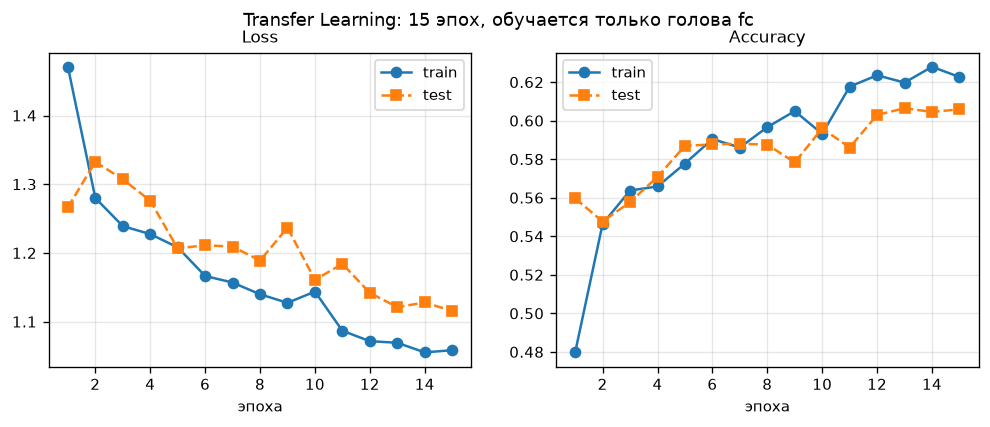

↓ 03_train_eval/outputs/02_confusion_matrix.png


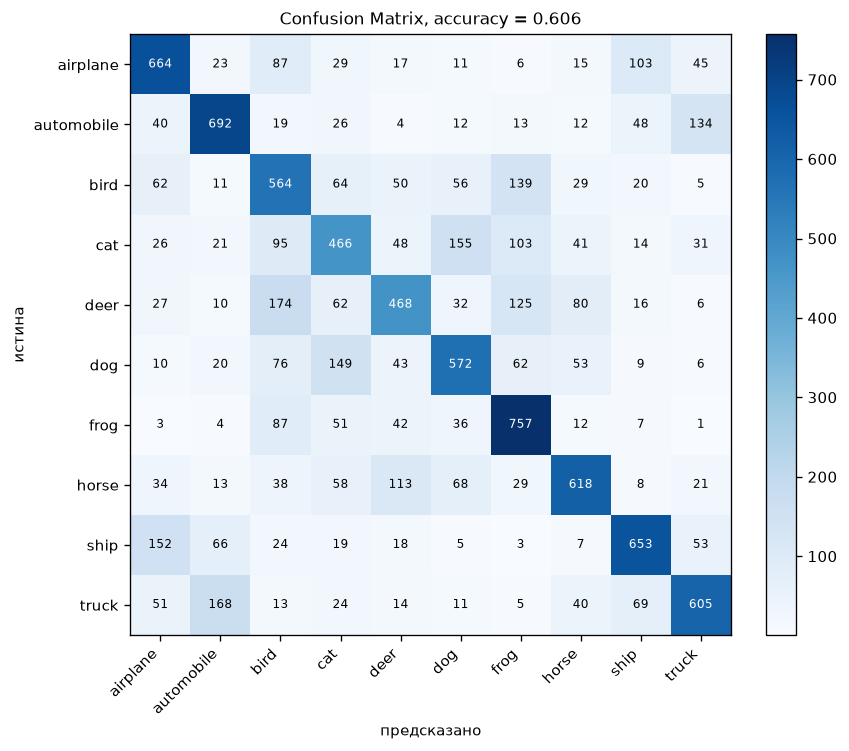

↓ 03_train_eval/outputs/03_misclassified.png


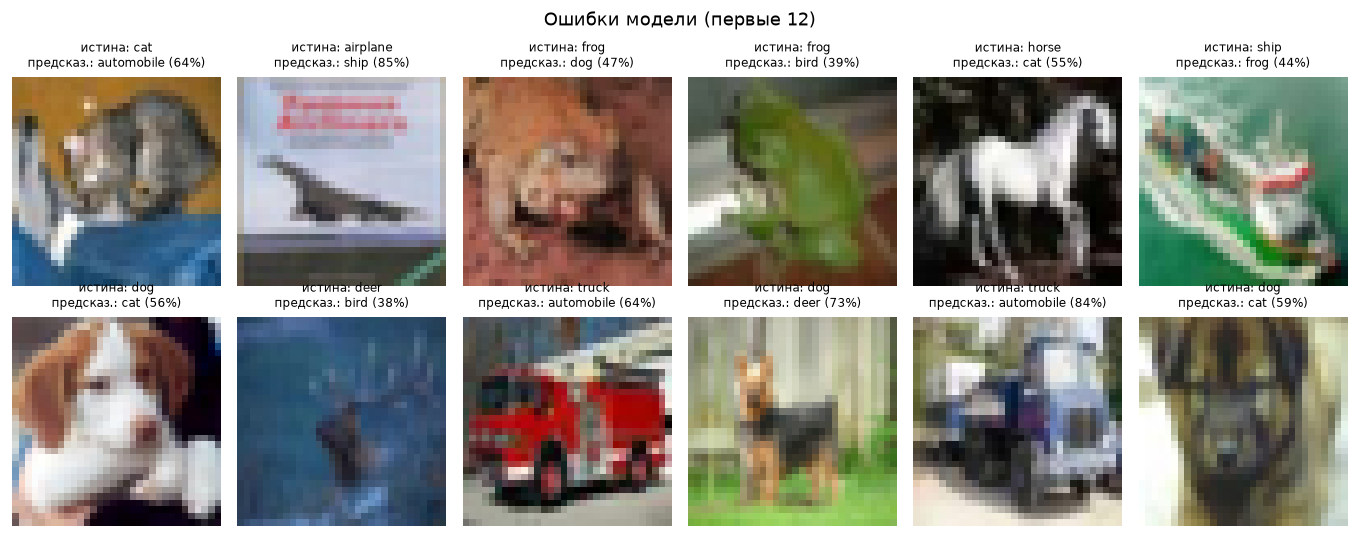

In [5]:
show("03_train_eval/outputs/01_training_curves.png")
show("03_train_eval/outputs/02_confusion_matrix.png", width=700)
show("03_train_eval/outputs/03_misclassified.png")

**Комментарий к confusion matrix.** Матрица почти симметрична по «животным» (cat ↔ dog, deer ↔ bird)
и по «технике» (automobile ↔ truck, airplane ↔ ship) — модель путает именно визуально близкие классы,
а не случайные. Внизу — первые 12 ошибок с уверенностью модели: например, размытый олень
определяется как птица, лошадь — как кошка, пожарная машина — как «automobile».

## Эксперимент: режим BatchNorm замороженного бэкенда

Первый прогон давал accuracy ≈ 0.34 и **не рос**. Проверили гипотезу: слои `BatchNorm` внутри
замороженного бэкенда в режиме `train` пересчитывают статистики под CIFAR-10, а их `weight/bias`
остаются от ImageNet и «подстроиться» не могут — признаки «плывут», распределение входа головы
меняется на каждом шаге. Если держать BN в `eval`, признаки по-настоящему заморожены.

| Режим BatchNorm | Accuracy | Macro-F1 |
|---|---|---|
| frozen | 0.6059 | 0.6049 |
| train | 0.4010 | 0.3987 |

Разница в 1.5 раза при тех же данных, эпохах и learning rate. Контрольный запуск
(`--compare-bn`) сохранён в `03_train_eval/outputs/04_curves_bn_other_mode.png` и
`05_confusion_bn_other.png`.

---
# 4. :star: Задание со звёздочкой — Fine-tuning и сравнение accuracy

**Что сделано.** Модель этапа 3 (обучена только голова) взята как baseline. Затем «последние слои»
(`layer4` + `fc`, 8.4 млн параметров) разморожены и дообучены на CIFAR-10 маленьким learning rate
(`lr = 1e-4` с косинусным затуханием, 5 эпох) — так предобученные веса подстраиваются под задачу,
но не разрушаются. Для контроля обучен такой же ResNet18 **с нуля** (случайная инициализация).

| Вариант | Accuracy | Macro-F1 | Δ к baseline |
|---|---|---|---|
| Обучение только головы (этап 3) | 0.6059 | 0.6049 | — |
| Fine-tuning: разморожены `layer4` + `fc` | 0.6499 | 0.6471 | 0.044 |
| Обучение с нуля (случайные веса) | 0.4257 | 0.4114 | -0.1802 |

**Ответ на вопрос задания**: accuracy **до** fine-tuning = 0.6059,
**после** = 0.6499 → прирост **+0.0440**.
Сравнение «с нуля» (0.4257) показывает, что передача обучения выигрывает у
обучения с нуля **+0.1802** — при том, что в первом
случае обучается в ~2000 раз меньше параметров.

↓ 04_fine_tuning_star/outputs/01_accuracy_compare.png


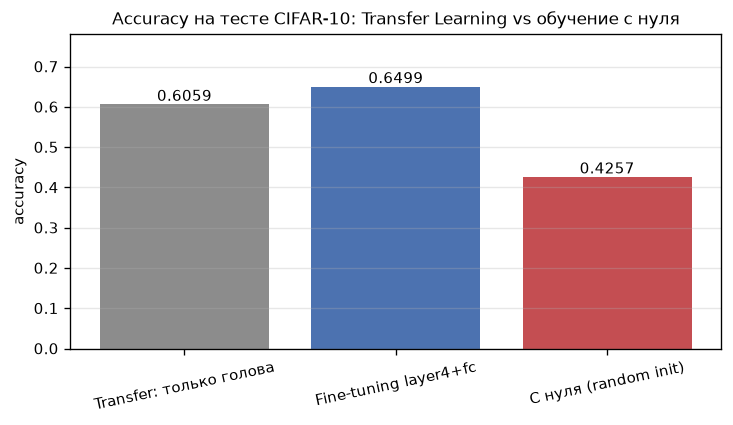

↓ 04_fine_tuning_star/outputs/curves_layer4.png


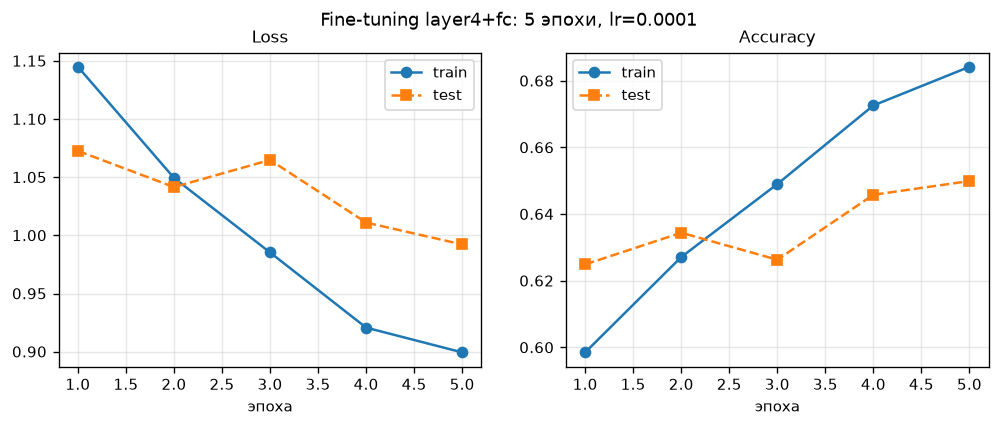

↓ 04_fine_tuning_star/outputs/curves_scratch.png


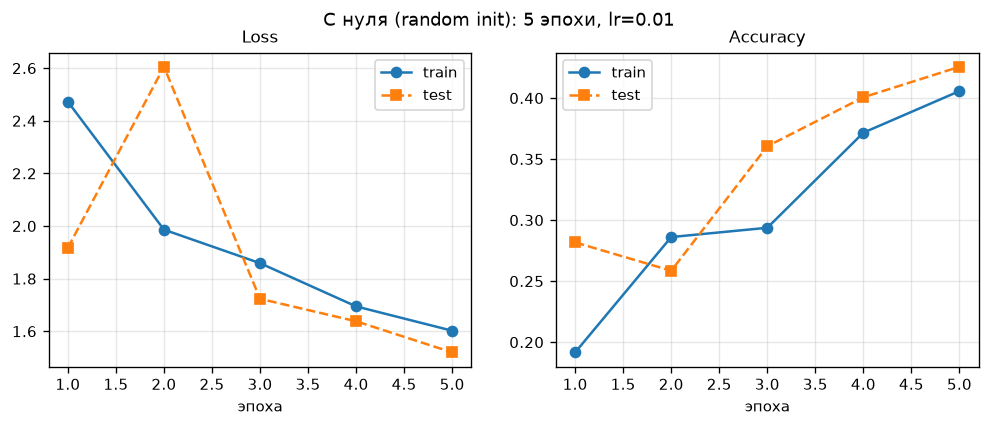

↓ 04_fine_tuning_star/outputs/confusion_layer4.png


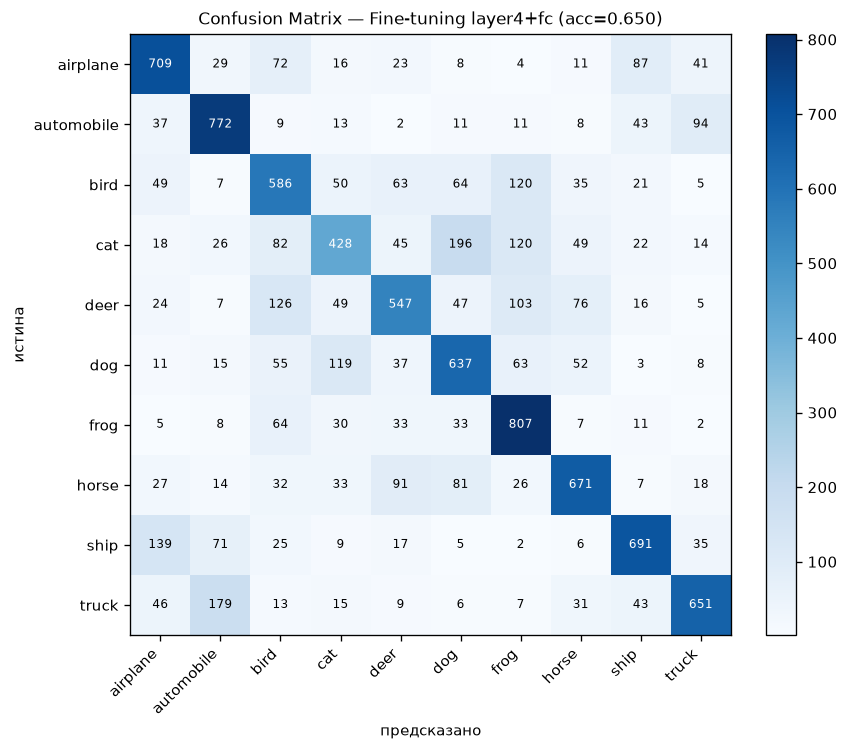

In [6]:
show("04_fine_tuning_star/outputs/01_accuracy_compare.png")
show("04_fine_tuning_star/outputs/curves_layer4.png",
     "04_fine_tuning_star/outputs/curves_scratch.png")
show("04_fine_tuning_star/outputs/confusion_layer4.png", width=700)

**Вывод по этапу.** Схема «сначала быстро обучить голову, затем аккуратно разморозить последние
блоки» даёт лучший результат; обучение всей сети с нуля на 10 000 картинок за 5 эпох заметно
проигрывает — сети банально нечем «наполнить» 11 млн весов.

---
# 5. ДЗ лекции 3 — один нейрон с Sigmoid на чистом Python (без PyTorch)

Это домашнее задание сдаётся отдельным файлом (`05_homework_neuron/Вопросы_лекции_3.md` —
ответы на вопросы про Трансформеры/RNN, `05_homework_neuron/main.py` — код). Здесь — краткий итог,
потому что задание напрямую связано с теорией нейросетей из лекции 3.

**Что реализовано (`math` + `random`, без PyTorch и numpy):** прямой проход `z = Σwᵢxᵢ + b`,
`a = σ(z)`; обратный проход по правилу цепочки `∂L/∂z = (a − y)·a·(1 − a)`, `∂L/∂wᵢ = ∂L/∂z · xᵢ`.

**Проверка корректности.** Аналитические градиенты сравнили с численной производной
(`(L(w+ε) − L(w−ε)) / 2ε`): максимальное расхождение **8.35e-12** — уровень
машинной точности. Отдельная сверка с `torch.autograd` (`cross_check_torch.py`) даёт 2.8e-17.

**Обучение на логических функциях** (градиентный спуск по 4 примерам, 500 эпох, lr = 1.0):

| Функция | loss (начало → конец) | accuracy | выученные веса |
|---|---|---|---|
| AND | 0.1279 → 0.013175 | 1.00 | w=(+2.88, +2.88), b=-4.43 |
| OR | 0.1483 → 0.007212 | 1.00 | w=(+3.59, +3.59), b=-1.50 |
| XOR | 0.1275 → 0.125000 | 0.75 | w=(-0.00, -0.00), b=+0.00 |

AND и OR линейно разделимы и решаются одним нейроном идеально; XOR — нет: перебор по сетке
`(w1, w2, b)` даёт максимум accuracy **0.75**, то есть одну прямую
нельзя «согнуть». Это ровно та причина, по которой понадобились скрытые слои (MLP), а затем — CNN.

↓ 05_homework_neuron/outputs/02_decision_boundary.png


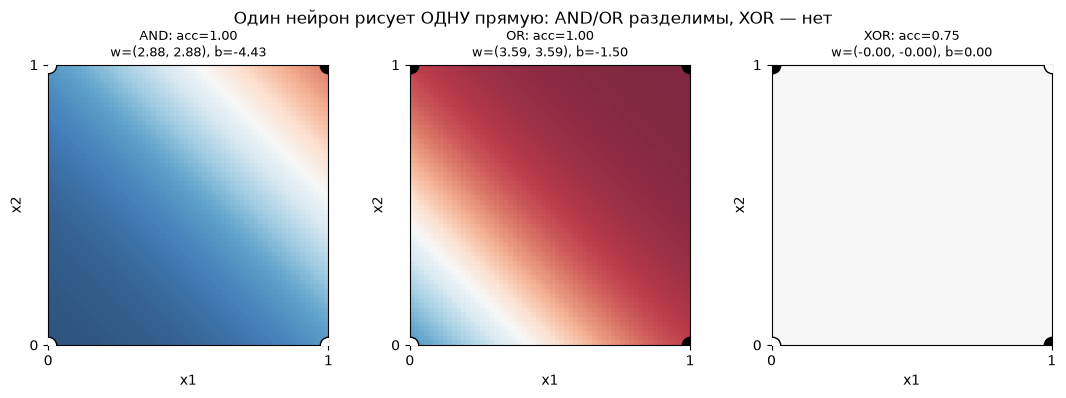

↓ 05_homework_neuron/outputs/01_training.png


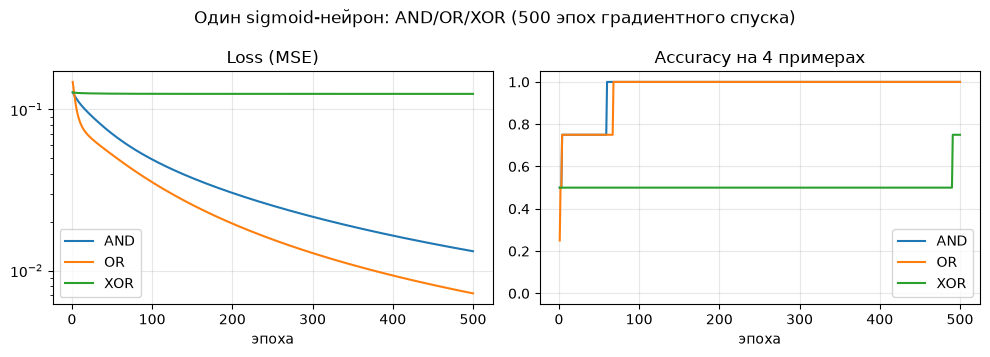

↓ 05_homework_neuron/outputs/03_gradient_check.png


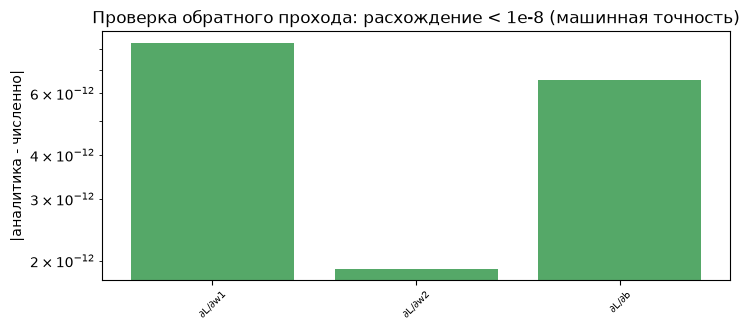

In [7]:
show("05_homework_neuron/outputs/02_decision_boundary.png")
show("05_homework_neuron/outputs/01_training.png", "05_homework_neuron/outputs/03_gradient_check.png")

---
# Выводы

1. **Transfer Learning работает на маленьких данных.** За 2.5 минуты обучения на CPU и 5 130
   обучаемых весов (0.05 % модели) получено accuracy **0.6059** на полном тесте
   CIFAR-10; после fine-tuning последнего блока — **0.6499**. Обучение той же
   сети с нуля даёт лишь 0.4257: предобученные признаки на ImageNet весят
   больше, чем 11 млн случайных весов.
2. **Аугментации + нормализация** расширяют датасет бесплатно: модель учит объект, а не конкретные
   пиксели (см. раздел 1).
3. **Ошибки модели содержательны**: путаются визуально близкие классы
   (cat ↔ dog, deer ↔ bird, automobile ↔ truck) — как и должно быть у модели, а не случайные ответы.
4. **Два инженерных грабля, найденных по ходу работы** (и измеренных, а не «на глаз»):
   * `BatchNorm` замороженного бэкенда обязан быть в режиме `eval` — иначе accuracy падает
     с 0.606 до 0.401;
   * стандартный ResNet18 рассчитан на 224×224, на 32×32 он «схлопывает» карту признаков до 1×1
     (лечится заменой входа на 3×3/`stride=1` или удалением `MaxPool`).
5. **Пределы применимости** видны на ДЗ: один нейрон с сигмоидой рисует **одну прямую** и не решает
   XOR — нелинейность и глубина нужны с самого начала, а CNN добавляет к этому учёт
   пространственной структуры изображения.

## Как воспроизвести

```bash
cd "Методы исскуственного ителекта/Практика_3_CNN_Transfer_Learning"
../.venv/bin/python 01_data_augmentation/main.py       # данные и аугментации (~30 с)
../.venv/bin/python 02_model_adaptation/main.py        # адаптация ResNet18 (~40 с)
../.venv/bin/python 03_train_eval/main.py --compare-bn  # обучение головы (~5.5 мин)
../.venv/bin/python 04_fine_tuning_star/main.py        # fine-tuning + «с нуля» (~11 мин)
../.venv/bin/python 05_homework_neuron/main.py         # ДЗ с лекции 3 (без PyTorch, ~20 с)
../.venv/bin/python build_report.py                    # пересобрать этот отчёт
```

Структура каталогов, все графики и подробные логи — в `README.md` и `results.md` каждой папки.